# Estimación del MIC con métodos de clasificación ordinal

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
import os
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV
from sklearn import metrics
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, StratifiedKFold

from sklearn.datasets import load_diabetes
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.preprocessing import LabelEncoder

from ordinal_class import OrdinalClassifier
from camda_functions import get_data, get_X_y_ordinal, split_stratified_into_train_val_test, search_params_ordinal
from camda_functions import get_X_ordinal_test, ordinal_clas_stat, results_report, assign_phenotype

Pipeline con datos completos (AMR count)
- Encoding TF-IDF
- Factorización SVD y NMF con *p* componentes
- Baseline: regresión lineal múltiple y RF para clasificacion o regresion
- Clasificadores ordinales basados en los siguientes clasificadores base:
    - Regresión Logística
    - CART
    - Random Forests
    - Neural Networks con recodificación ordinal de $y$
- Comparación de resultados

In [28]:
label_file = 'strict_acinetobacter'
metadata_train, tr_data = get_data(data_file = label_file + '_train', zipped=True)
metadata_test, te_data = get_data(data_file = label_file + '_test', zipped=True)

In [62]:
os.getcwd()

'/Users/vmac/cursos/estadistica_microbiomas/2024/camda2025/scripts'

### Variables $(\mathbf{X}, \mathbf{y})$

- Se obtiene la variable independiente $X$ según el pipeline (TF-IDF -> LSA/NMF) para train y test
- Se obtiene la variable dependiente $y$ para train y test, con el MIC recategorizado según ciertos bins. Se convierte a una variable categórica tipo string y también, se codifica como una variable int mediante un label encoder (le), que también se devuelve
- Adicinoalmente, se devuelven los metadatos para train y test, que contienen los valores originales del MIC

Metadatos para train y test

Rutas para datos y demás información para entrenar modelos por cada antibiótico

In [3]:
ruta_fact = '/Users/vmac/cursos/estadistica_microbiomas/2024/camda2025/data_models/' # si hay alguna factorización guardada...
n_comp = 100 #cuántos componentes?

In [4]:
# obtengo las transformaciones y demás información para clasificación ordinal en datos de train
tfidf, tfidf_vect, amr_lsa, amr_nmf, Y, le = \
    get_X_y_ordinal(metadata=metadata_train, amr_count=tr_data, data_label=label_file, only_counts = False, exist_fact = False, 
                    exist_vect = False, fact_path = ruta_fact, n_comp = n_comp)


In [7]:
# si hay modelos guardados para las transformaciones...
#tfidf, tfidf_vect, amr_lsa, amr_nmf, Y, le = \
#    get_X_y_ordinal2(data_path=ruta_data, data_label=data_label, only_counts = False, exist_fact = True, 
#                    exist_vect = True, fact_path = ruta_fact, n_comp = n_comp)

Datos de prueba (sin etiquetas)

In [5]:
# transformaciones para datos de test  (sin valores de respuesta)
data_te, amr_lsa_te, amr_nmf_te = \
    get_X_ordinal_test(amr_count=te_data, data_label=label_file, only_counts = False, fact_path = ruta_fact)

X_test_original = amr_lsa_te

In [6]:
counts_mic = Y['MIC_str'].value_counts()
counts_mic

MIC_str
64.0    184
16.0    116
4.0      45
8.0      43
32.0     41
2.0      15
1.0       3
0.5       2
Name: count, dtype: int64

### Clasificación

Se obtienen datos de entrenamiento y prueba

In [7]:
X = amr_lsa
y_cat = Y['MIC_cat']

X_train, y_train, __, __, X_test, y_test, class_w, __ = \
        split_stratified_into_train_val_test(X, y_cat, .80, 0, .20, 
        std=False, two_subsets=True, random_state=42)

In [8]:
# para formar la variable de respuesta del problema de regresión, se pueden elegir dos opciones de MIC:
# - el 'mic' original, posiblemente con más valores diferentes que los considerados en las categorias ordinales (se reagruparon los valores poco frecuentes)
# - el recategorizado 'mic_recat', donde se reagruparon los valores poco frecuentes de concentración
y_train_reg = Y.loc[list(X_train.index)]['MIC_recat']
y_test_reg = Y.loc[list(X_test.index)]['MIC_recat']

Creo las tablas de metadatos para train y validacion

In [9]:
Spec_Antibiotic_train = metadata_train.loc[list(X_train.index)]
Spec_Antibiotic_test = metadata_train.loc[list(X_test.index)]
#Spec_Antibiotic_test


Pipeline propuesto:
1. Datos completos
- TF-IDF
- Factorización SVD o NMF con *p* componentes
- Visualización de baja dimensión
- Baseline: regresión lineal múltiple y RF para clasificacion o regresion
- Clasificadores ordinales:
    - Reg. Log.
    - CART
    - RF
    - NN
- Comparación de resultados

2. Datos seleccionados
- TF-IDF
- Selección de variables usando
    - RF
    - RFE
- Factorización SVD o NMF con *p* componentes
- Visualización de baja dimensión
- Baseline: regresión lineal múltiple y RF para clasificacion o regresion
- Clasificadores ordinales:
    - Reg. Log.
    - CART
    - RF
    - NN
- Comparación de resultados

#### Visualizaciones de baja dimensión

#### Baselines y clasificación ordinal

In [11]:
# linear model
from sklearn.linear_model import LinearRegression 

# CART
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn import tree

# Boosting
from sklearn.ensemble import AdaBoostClassifier 
from sklearn.tree import DecisionTreeClassifier

# Bagging
from sklearn.ensemble import BaggingClassifier

# Random Forest
from sklearn.ensemble import RandomForestClassifier

# Logistic Regression
from sklearn.linear_model import LogisticRegression

Baselines

In [12]:
linear_reg = LinearRegression()
linear_reg.fit(X_train.to_numpy(), y_train_reg.to_numpy())
y_pred = linear_reg.predict(X_test)
mae = mean_absolute_error(y_test_reg, y_pred)
rmse = root_mean_squared_error(y_test_reg, y_pred)
print('MAE: ', mae, '. RMSE: ',rmse)

MAE:  18.87591997981083 . RMSE:  35.8592407476122


In [13]:
cart_reg = DecisionTreeRegressor().fit(X_train, y_train_reg)
y_pred = cart_reg.predict(X_test)
mae = mean_absolute_error(y_test_reg, y_pred)
rmse = root_mean_squared_error(y_test_reg, y_pred)
print('MAE: ', mae, '. RMSE: ',rmse)

MAE:  13.329360269360269 . RMSE:  21.008602573799788


## Regresión logística ordinal

In [14]:
# Definir los parámetros para GridSearchCV
param_grid = {
    'clf__C': [0.01, 0.1, 1, 2, 3, 4, 5, 10, 15],
    'clf__penalty': ['l1', 'l2', 'elasticnet']
}
# Crear instancia del clasificador con Logistic Regression
LR = LogisticRegression(max_iter=5000, solver='saga')
# Crear instancia de OrdinalClassifier con Logistic Regression como clasificador base
ordinal_clf = OrdinalClassifier(LR)
cv = 5
best_params, best_score = search_params_ordinal(ordinal_clf, X_train, y_train, param_grid, cv)
print("Mejores hiperparámetros:", best_params)
print("Mejor puntuación:", best_score)

Mejores hiperparámetros: {'clf__C': 2, 'clf__penalty': 'l1'}
Mejor puntuación: 0.6490219092331768


In [15]:
# Realiza K-FOLD CV para obtener estadísticas de desempeño
LR = LogisticRegression(max_iter=5000, C = best_params['clf__C'], penalty = best_params['clf__penalty'], solver = 'saga')
# Crear una nueva instancia de OrdinalClassifier con los parámetros óptimos
best_model = OrdinalClassifier(LR)

n_repeats = 10
sc='neg_mean_absolute_error' #MAE
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, sc, rand_state = 42, n_repeats=n_repeats)
# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"MAE: {mean_score:.3f} +/- {std_score:.3f}")


CV- 50  Folds
MAE: 1.117 +/- 0.166


In [16]:
sc='neg_root_mean_squared_error' #RMSE
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, sc, rand_state = 42, n_repeats=n_repeats)

# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"RMSE: {mean_score:.3f} +/- {std_score:.3f}")

CV- 50  Folds
RMSE: 2.014 +/- 0.178


MAE:  1.044 
RMSE:  1.926
              precision    recall  f1-score   support

         1.0       0.00      0.00      0.00         1
        16.0       0.67      0.70      0.68        23
         2.0       0.00      0.00      0.00         3
        32.0       0.67      0.50      0.57         8
         4.0       0.43      0.33      0.38         9
        64.0       0.67      0.86      0.75        37
         8.0       0.80      0.44      0.57         9

    accuracy                           0.66        90
   macro avg       0.46      0.41      0.42        90
weighted avg       0.63      0.66      0.63        90



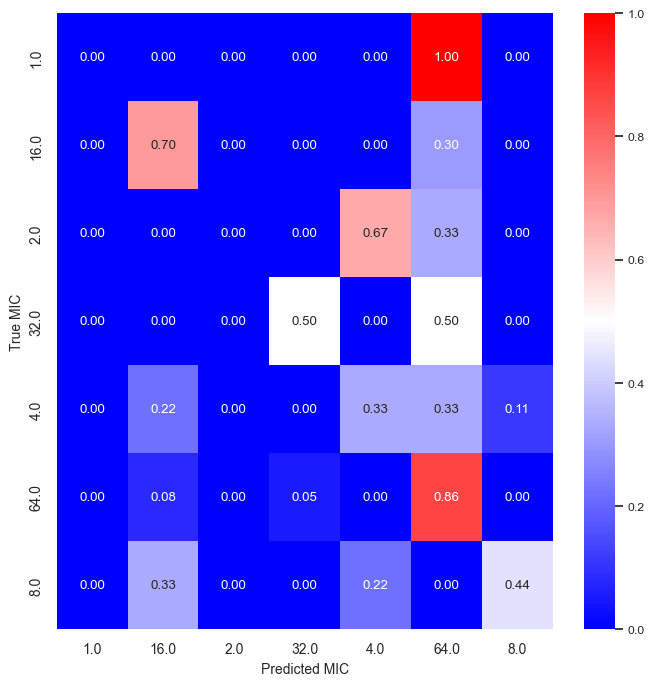

In [17]:
# entrena el modelo con los parámetros óptimos y hace la predicción en los datos de test
best_model.fit(X_train, y_train)
# Predecir etiquetas
y_hat = best_model.predict(X_test)

results_report(y_test, y_hat, le)

In [18]:
# metadatos y prediccion
res_path = '/Users/vmac/cursos/estadistica_microbiomas/2024/camda2025/results/'
Spec_Antibiotic_test['MIC_pred'] = le.inverse_transform(y_hat)
nf = res_path + 'AMRlsa_ordinal_logReg_'+label_file +'_test.csv'
Spec_Antibiotic_test.to_csv(nf)
Spec_Antibiotic_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred
biosample,,,,,,,,,,,
SRS2403193,Acinetobacter baumannii,Acinetobacter baumannii,0.983257,SRR5891485,ENA_SAMN07445119,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS1442612,Acinetobacter baumannii,Acinetobacter baumannii,0.983289,SRR3536229,ENA_SAMN04993368,CAZ,Resistant,Resistant,32.0,32.0,32.0
SRS2379970,Acinetobacter baumannii,Acinetobacter baumannii,0.983429,SRR5862467,ENA_SAMN07410719,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS927393,Acinetobacter baumannii,Acinetobacter baumannii,0.982716,SRR2075882,ENA_SAMN03576361,CAZ,Resistant,Resistant,256.0,64.0,64.0
SRS1336865,Acinetobacter baumannii,Acinetobacter nosocomialis,0.983283,SRR3222486,ENA_SAMN04546718,CAZ,Susceptible,Susceptible,4.0,4.0,64.0
...,...,...,...,...,...,...,...,...,...,...,...
SRS1337896,Acinetobacter baumannii,Acinetobacter baumannii,0.983487,SRR3223915,ENA_SAMN04549502,CAZ,Intermediate,Resistant,16.0,16.0,64.0
SRS1296936,Acinetobacter baumannii,Acinetobacter baumannii,0.982624,SRR3170768,ENA_SAMN04491433,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS2407853,Acinetobacter baumannii,Acinetobacter baumannii,0.983495,SRR5901132,ENA_SAMN07450848,CAZ,Resistant,Resistant,64.0,64.0,64.0


Predicción de datos sin etiquetas (test original)

In [20]:
# predicciones en datos de test  (sin valores de respuesta)
y_hat_original = best_model.predict(X_test_original)
metadata_test['MIC_pred'] = le.inverse_transform(y_hat_original)
feno_pred = assign_phenotype(metadata_test, spec_col = 'gtdb_species', mic_col = 'MIC_pred')
metadata_test['predicted_phenotype'] = feno_pred
nf = res_path + 'AMRlsa_ordinal_logReg_'+label_file +'_testPrediction.csv'
metadata_test.to_csv(nf)
metadata_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred,predicted_phenotype
biosample,,,,,,,,,,,,
SRS2078105,Klebsiella pneumoniae,Acinetobacter baumannii,0.977117,SRR5385772,ENA_SAMN06437933,GEN,?,?,?,?,64.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR3242007,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807653,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807654,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807655,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
...,...,...,...,...,...,...,...,...,...,...,...,...
SRS2174320,Acinetobacter baumannii,Acinetobacter baumannii,0.983208,SRR5519812,ENA_SAMN06892314,CAZ,?,?,?,?,4.0,Susceptible
SRS2174318,Acinetobacter baumannii,Acinetobacter baumannii,0.982833,SRR5519810,ENA_SAMN06892315,CAZ,?,?,?,?,2.0,Susceptible
SRS2174317,Acinetobacter baumannii,Acinetobacter baumannii,0.983067,SRR5519809,ENA_SAMN06892316,CAZ,?,?,?,?,4.0,Susceptible


## CART ordinal

In [21]:
# Definir los parámetros para GridSearchCV
param_grid = {
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__ccp_alpha': [0.1, 0.01, 0.05, 0.001, 0.005, 0.0001, 0.0005],
    'clf__max_features': ['auto', 'sqrt', 'log2'],
}
# Crear instancia del clasificador
DT = DecisionTreeClassifier()
# Crear instancia de OrdinalClassifier 
ordinal_clf = OrdinalClassifier(DT)
cv = 5
best_params, best_score = search_params_ordinal(ordinal_clf, X_train, y_train, param_grid, cv)
print("Mejores hiperparámetros:", best_params)
print("Mejor puntuación:", best_score)

Mejores hiperparámetros: {'clf__ccp_alpha': 0.01, 'clf__criterion': 'entropy', 'clf__max_features': 'sqrt'}
Mejor puntuación: 0.5292644757433489


In [22]:
# Crear una nueva instancia del clasificador ordinal
DT = DecisionTreeClassifier(ccp_alpha = best_params['clf__ccp_alpha'],
                            criterion = best_params['clf__criterion'],
                            max_features = best_params['clf__max_features'])

# Crear una nueva instancia de OrdinalClassifier con LogisticRegression actualizado
best_model = OrdinalClassifier(DT)

n_repeats = 10
sc='neg_mean_absolute_error'
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, score=sc, rand_state = 42, n_repeats=n_repeats)
# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"MAE: {mean_score:.3f} +/- {std_score:.3f}")

CV- 50  Folds
MAE: 1.218 +/- 0.147


In [23]:
sc='neg_root_mean_squared_error' #RMSE
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, score=sc, rand_state = 42, n_repeats=n_repeats)

# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"RMSE: {mean_score:.3f} +/- {std_score:.3f}")

CV- 50  Folds
RMSE: 1.971 +/- 0.179


MAE:  1.044 
RMSE:  1.844
              precision    recall  f1-score   support

         1.0       0.00      0.00      0.00         1
        16.0       0.63      0.83      0.72        23
         2.0       0.00      0.00      0.00         3
        32.0       0.31      0.50      0.38         8
         4.0       0.30      0.33      0.32         9
        64.0       0.83      0.65      0.73        37
         8.0       1.00      0.33      0.50         9

    accuracy                           0.59        90
   macro avg       0.44      0.38      0.38        90
weighted avg       0.66      0.59      0.60        90



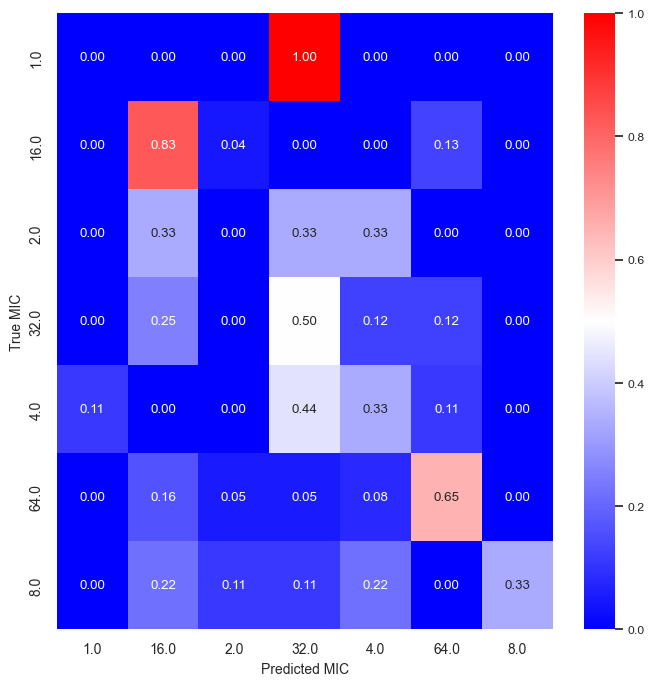

In [24]:
# entrena el modelo con los parámetros óptimos y hace la predicción en los datos de test
best_model.fit(X_train, y_train)
# Predecir etiquetas
y_hat = best_model.predict(X_test)

results_report(y_test, y_hat, le)

In [25]:
# metadatos y prediccion
Spec_Antibiotic_test['MIC_pred'] = le.inverse_transform(y_hat)
nf = res_path + 'AMRlsa_ordinal_CART_'+label_file+'_test.csv'
Spec_Antibiotic_test.to_csv(nf)
Spec_Antibiotic_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred
biosample,,,,,,,,,,,
SRS2403193,Acinetobacter baumannii,Acinetobacter baumannii,0.983257,SRR5891485,ENA_SAMN07445119,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS1442612,Acinetobacter baumannii,Acinetobacter baumannii,0.983289,SRR3536229,ENA_SAMN04993368,CAZ,Resistant,Resistant,32.0,32.0,32.0
SRS2379970,Acinetobacter baumannii,Acinetobacter baumannii,0.983429,SRR5862467,ENA_SAMN07410719,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS927393,Acinetobacter baumannii,Acinetobacter baumannii,0.982716,SRR2075882,ENA_SAMN03576361,CAZ,Resistant,Resistant,256.0,64.0,64.0
SRS1336865,Acinetobacter baumannii,Acinetobacter nosocomialis,0.983283,SRR3222486,ENA_SAMN04546718,CAZ,Susceptible,Susceptible,4.0,4.0,32.0
...,...,...,...,...,...,...,...,...,...,...,...
SRS1337896,Acinetobacter baumannii,Acinetobacter baumannii,0.983487,SRR3223915,ENA_SAMN04549502,CAZ,Intermediate,Resistant,16.0,16.0,2.0
SRS1296936,Acinetobacter baumannii,Acinetobacter baumannii,0.982624,SRR3170768,ENA_SAMN04491433,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS2407853,Acinetobacter baumannii,Acinetobacter baumannii,0.983495,SRR5901132,ENA_SAMN07450848,CAZ,Resistant,Resistant,64.0,64.0,64.0


Predicción de datos sin etiquetas (test original)

In [29]:
# predicciones en datos de test  (sin valores de respuesta)
y_hat_original = best_model.predict(X_test_original)
metadata_test['MIC_pred'] = le.inverse_transform(y_hat_original)
feno_pred = assign_phenotype(metadata_test, spec_col = 'gtdb_species', mic_col = 'MIC_pred')
metadata_test['predicted_phenotype'] = feno_pred
nf = res_path + 'AMRlsa_ordinal_CART_'+label_file +'_testPrediction.csv'
metadata_test.to_csv(nf)
metadata_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred,predicted_phenotype
biosample,,,,,,,,,,,,
SRS2078105,Klebsiella pneumoniae,Acinetobacter baumannii,0.977117,SRR5385772,ENA_SAMN06437933,GEN,?,?,?,?,4.0,Susceptible
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR3242007,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807653,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807654,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807655,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
...,...,...,...,...,...,...,...,...,...,...,...,...
SRS2174320,Acinetobacter baumannii,Acinetobacter baumannii,0.983208,SRR5519812,ENA_SAMN06892314,CAZ,?,?,?,?,4.0,Susceptible
SRS2174318,Acinetobacter baumannii,Acinetobacter baumannii,0.982833,SRR5519810,ENA_SAMN06892315,CAZ,?,?,?,?,2.0,Susceptible
SRS2174317,Acinetobacter baumannii,Acinetobacter baumannii,0.983067,SRR5519809,ENA_SAMN06892316,CAZ,?,?,?,?,32.0,Resistant


## Random Forests ordinal

In [30]:
# Definir los parámetros para GridSearchCV
param_grid = {
    'clf__n_estimators': [50, 100, 200, 500],
    'clf__criterion': ['gini', 'entropy', 'log_loss'],
    'clf__class_weight': ['balanced', 'balanced_subsample'],
    'clf__ccp_alpha': [0.1, 0.01, 0.05, 0.001, 0.005, 0.0001, 0.0005],
    'clf__max_features': ['sqrt', 'log2']
}

# Crear instancia del clasificador
RF = RandomForestClassifier()
# Crear instancia de OrdinalClassifier 
ordinal_clf = OrdinalClassifier(RF)
cv = 5
best_params, best_score = search_params_ordinal(ordinal_clf, X_train, y_train, param_grid, cv)
print("Mejores hiperparámetros:", best_params)
print("Mejor puntuación:", best_score)

Mejores hiperparámetros: {'clf__ccp_alpha': 0.01, 'clf__class_weight': 'balanced', 'clf__criterion': 'gini', 'clf__max_features': 'sqrt', 'clf__n_estimators': 200}
Mejor puntuación: 0.6491784037558685


In [31]:
# Crear una nueva instancia del clasificador ordinal
RF = RandomForestClassifier(n_estimators = best_params['clf__n_estimators'],
                            criterion = best_params['clf__criterion'],
                            class_weight = best_params['clf__class_weight'],
                            ccp_alpha = best_params['clf__ccp_alpha'],
                            max_features = best_params['clf__max_features'])

# Crear una nueva instancia de OrdinalClassifier con LogisticRegression actualizado
best_model = OrdinalClassifier(RF)

n_repeats = 10
sc='neg_mean_absolute_error'
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, score=sc, rand_state = 42, n_repeats=n_repeats)

# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"MAE: {mean_score:.3f} +/- {std_score:.3f}")

CV- 50  Folds
MAE: 1.052 +/- 0.122


In [32]:
sc='neg_root_mean_squared_error' #RMSE
mean_score, std_score, cv_scores = ordinal_clas_stat(best_model, X_train, y_train, score=sc, rand_state = 42, n_repeats=n_repeats)

# Imprimir los resultados de la validación cruzada
print("CV-",len(cv_scores),' Folds')
print(f"RMSE: {mean_score:.3f} +/- {std_score:.3f}")

CV- 50  Folds
RMSE: 1.932 +/- 0.156


MAE:  0.989 
RMSE:  1.871
              precision    recall  f1-score   support

         1.0       0.00      0.00      0.00         1
        16.0       0.65      0.87      0.74        23
         2.0       0.00      0.00      0.00         3
        32.0       0.80      0.50      0.62         8
         4.0       0.43      0.33      0.38         9
        64.0       0.74      0.78      0.76        37
         8.0       0.71      0.56      0.62         9

    accuracy                           0.68        90
   macro avg       0.48      0.43      0.45        90
weighted avg       0.66      0.68      0.66        90



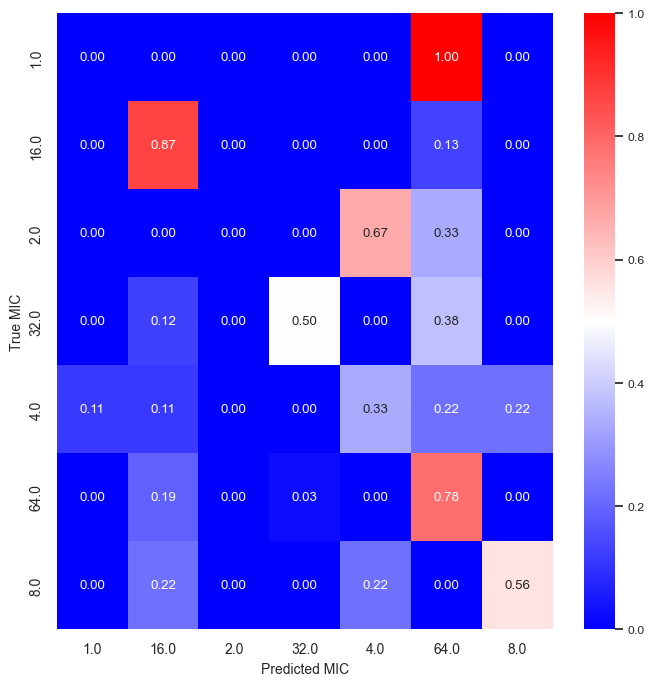

In [33]:
best_model.fit(X_train, y_train)
# Predecir etiquetas
y_hat = best_model.predict(X_test)

results_report(y_test, y_hat, le)

In [34]:
# metadatos y prediccion
Spec_Antibiotic_test['MIC_pred'] = le.inverse_transform(y_hat)
nf = res_path + 'AMRlsa_ordinal_RandomForest_'+label_file+'_test.csv'
Spec_Antibiotic_test.to_csv(nf)
Spec_Antibiotic_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred
biosample,,,,,,,,,,,
SRS2403193,Acinetobacter baumannii,Acinetobacter baumannii,0.983257,SRR5891485,ENA_SAMN07445119,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS1442612,Acinetobacter baumannii,Acinetobacter baumannii,0.983289,SRR3536229,ENA_SAMN04993368,CAZ,Resistant,Resistant,32.0,32.0,32.0
SRS2379970,Acinetobacter baumannii,Acinetobacter baumannii,0.983429,SRR5862467,ENA_SAMN07410719,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS927393,Acinetobacter baumannii,Acinetobacter baumannii,0.982716,SRR2075882,ENA_SAMN03576361,CAZ,Resistant,Resistant,256.0,64.0,64.0
SRS1336865,Acinetobacter baumannii,Acinetobacter nosocomialis,0.983283,SRR3222486,ENA_SAMN04546718,CAZ,Susceptible,Susceptible,4.0,4.0,64.0
...,...,...,...,...,...,...,...,...,...,...,...
SRS1337896,Acinetobacter baumannii,Acinetobacter baumannii,0.983487,SRR3223915,ENA_SAMN04549502,CAZ,Intermediate,Resistant,16.0,16.0,64.0
SRS1296936,Acinetobacter baumannii,Acinetobacter baumannii,0.982624,SRR3170768,ENA_SAMN04491433,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS2407853,Acinetobacter baumannii,Acinetobacter baumannii,0.983495,SRR5901132,ENA_SAMN07450848,CAZ,Resistant,Resistant,64.0,64.0,64.0


Predicción de datos sin etiquetas (test original)

In [35]:
# predicciones en datos de test  (sin valores de respuesta)
y_hat_original = best_model.predict(X_test_original)
metadata_test['MIC_pred'] = le.inverse_transform(y_hat_original)
feno_pred = assign_phenotype(metadata_test, spec_col = 'gtdb_species', mic_col = 'MIC_pred')
metadata_test['predicted_phenotype'] = feno_pred
nf = res_path + 'AMRlsa_ordinal_RandomForest_'+label_file +'_testPrediction.csv'
metadata_test.to_csv(nf)
metadata_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred,predicted_phenotype
biosample,,,,,,,,,,,,
SRS2078105,Klebsiella pneumoniae,Acinetobacter baumannii,0.977117,SRR5385772,ENA_SAMN06437933,GEN,?,?,?,?,64.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR3242007,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807653,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807654,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807655,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
...,...,...,...,...,...,...,...,...,...,...,...,...
SRS2174320,Acinetobacter baumannii,Acinetobacter baumannii,0.983208,SRR5519812,ENA_SAMN06892314,CAZ,?,?,?,?,4.0,Susceptible
SRS2174318,Acinetobacter baumannii,Acinetobacter baumannii,0.982833,SRR5519810,ENA_SAMN06892315,CAZ,?,?,?,?,2.0,Susceptible
SRS2174317,Acinetobacter baumannii,Acinetobacter baumannii,0.983067,SRR5519809,ENA_SAMN06892316,CAZ,?,?,?,?,4.0,Susceptible


## Red neuronal ordinal

In [36]:
from camda_functions import ordinal_encoding_nn, prediction2label_nn, cross_val_metrics_nn

X_train_np = np.array(X_train)
X_test_np = np.array(X_test)

# recodificar la variable de respuesta con un encoding ordinal
n_clas = len(le.classes_)
n_var = X_train_np.shape[1]
y_tr_oc = ordinal_encoding_nn(y_train, n_clas)
y_te_oc = ordinal_encoding_nn(y_test, n_clas)

In [37]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras import activations

# Crear una instancia del modelo
model = Sequential()
#model.add(Dropout(0.2, input_shape = (n_var,)))
#model.add(Dense(80, activation='relu'))
model.add(Dense(80, input_dim=n_var, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(60, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(30, activation='relu'))
model.add(Dense(n_clas, activation='sigmoid'))  # Output layer with 5 units for target representation

# Compile the model
model.compile(loss='binary_crossentropy', optimizer='adam')

In [38]:
# Cross validation
cv = 5
mae_mean, mae_std, rmse_mean, rmse_std = cross_val_metrics_nn(model, X_train_np, y_tr_oc, cv)
# Imprimir los resultados
print(f"MAE: {mae_mean} +/- {mae_std}")
print(f"RMSE: {rmse_mean} +/- {rmse_std}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 606us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 585us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 589us/step
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 623us/step
MAE: 0.7957746478873239 +/- 0.28496018087068886
RMSE: 1.6363108596975064 +/- 0.32409509585287155


3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 635us/step
MAE:  1.044 
RMSE:  1.903
              precision    recall  f1-score   support

         1.0       0.00      0.00      0.00         1
        16.0       0.61      0.87      0.71        23
         2.0       1.00      0.33      0.50         3
        32.0       0.57      0.50      0.53         8
         4.0       0.40      0.22      0.29         9
        64.0       0.68      0.70      0.69        37
         8.0       1.00      0.56      0.71         9

    accuracy                           0.64        90
   macro avg       0.61      0.45      0.49        90
weighted avg       0.66      0.64      0.63        90



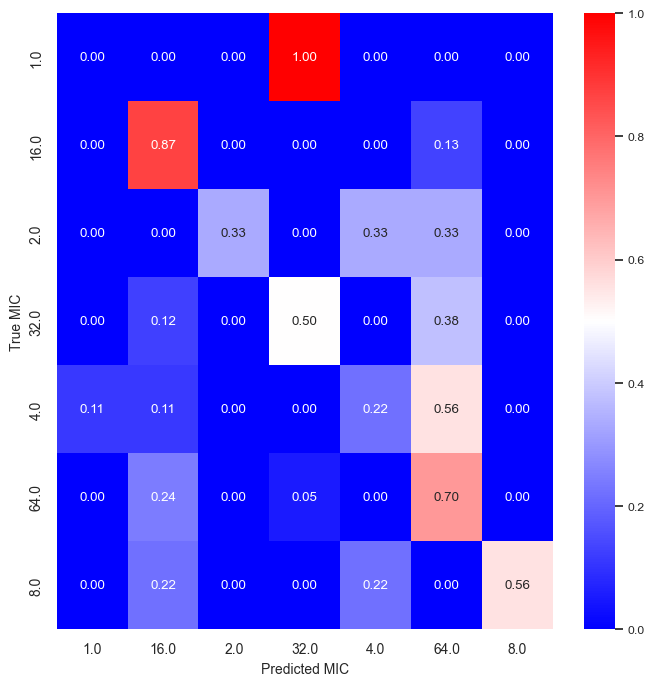

In [39]:
# Train the model
model.fit(X_train_np, y_tr_oc, epochs=50, batch_size=16, validation_data=(X_test_np, y_te_oc), verbose=False)
y_hat = prediction2label_nn(model.predict(X_test))
results_report(y_test, y_hat, le)

In [40]:
# metadatos y prediccion
Spec_Antibiotic_test['MIC_pred'] = le.inverse_transform(y_hat)
nf = res_path + 'AMRlsa_ordinal_NeuralNet_'+label_file+'_test.csv'
Spec_Antibiotic_test.to_csv(nf)
Spec_Antibiotic_test

,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred
biosample,,,,,,,,,,,
SRS2403193,Acinetobacter baumannii,Acinetobacter baumannii,0.983257,SRR5891485,ENA_SAMN07445119,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS1442612,Acinetobacter baumannii,Acinetobacter baumannii,0.983289,SRR3536229,ENA_SAMN04993368,CAZ,Resistant,Resistant,32.0,32.0,32.0
SRS2379970,Acinetobacter baumannii,Acinetobacter baumannii,0.983429,SRR5862467,ENA_SAMN07410719,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS927393,Acinetobacter baumannii,Acinetobacter baumannii,0.982716,SRR2075882,ENA_SAMN03576361,CAZ,Resistant,Resistant,256.0,64.0,32.0
SRS1336865,Acinetobacter baumannii,Acinetobacter nosocomialis,0.983283,SRR3222486,ENA_SAMN04546718,CAZ,Susceptible,Susceptible,4.0,4.0,64.0
...,...,...,...,...,...,...,...,...,...,...,...
SRS1337896,Acinetobacter baumannii,Acinetobacter baumannii,0.983487,SRR3223915,ENA_SAMN04549502,CAZ,Intermediate,Resistant,16.0,16.0,64.0
SRS1296936,Acinetobacter baumannii,Acinetobacter baumannii,0.982624,SRR3170768,ENA_SAMN04491433,CAZ,Resistant,Resistant,64.0,64.0,64.0
SRS2407853,Acinetobacter baumannii,Acinetobacter baumannii,0.983495,SRR5901132,ENA_SAMN07450848,CAZ,Resistant,Resistant,64.0,64.0,64.0


Predicción de datos sin etiquetas (test original)

In [41]:
# predicciones en datos de test  (sin valores de respuesta)
y_hat_original = prediction2label_nn(model.predict(X_test_original))
metadata_test['MIC_pred'] = le.inverse_transform(y_hat_original)
feno_pred = assign_phenotype(metadata_test, spec_col = 'gtdb_species', mic_col = 'MIC_pred')
metadata_test['predicted_phenotype'] = feno_pred
nf = res_path + 'AMRlsa_ordinal_NeuralNet_'+label_file +'_testPrediction.csv'
metadata_test.to_csv(nf)
metadata_test

19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 399us/step


,camda_species,gtdb_species,gtdb_ani,accession,genome,antibiotic,camda_phenotype,assigned_phenotype,camda_mic,recategorized_mic,MIC_pred,predicted_phenotype
biosample,,,,,,,,,,,,
SRS2078105,Klebsiella pneumoniae,Acinetobacter baumannii,0.977117,SRR5385772,ENA_SAMN06437933,GEN,?,?,?,?,64.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR3242007,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807653,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807654,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
SRS1350020,Acinetobacter baumannii,Acinetobacter baumannii,0.982582,SRR6807655,ENA_SAMN04014893,CAZ,?,?,?,?,16.0,Resistant
...,...,...,...,...,...,...,...,...,...,...,...,...
SRS2174320,Acinetobacter baumannii,Acinetobacter baumannii,0.983208,SRR5519812,ENA_SAMN06892314,CAZ,?,?,?,?,4.0,Susceptible
SRS2174318,Acinetobacter baumannii,Acinetobacter baumannii,0.982833,SRR5519810,ENA_SAMN06892315,CAZ,?,?,?,?,2.0,Susceptible
SRS2174317,Acinetobacter baumannii,Acinetobacter baumannii,0.983067,SRR5519809,ENA_SAMN06892316,CAZ,?,?,?,?,4.0,Susceptible
